In [1]:
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms
from torchvision import models

from time import time
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


Перенос стиля с одного изображения на другое есть во многом задача переноса текстуры. В статье $Gatys\space et \space al. \space 2016$ используется результат из статьи $2015$ года от тех же авторов, где представлен алгоритм генерации новой текстуры из уже существующего изображения с помощью CNN, а именно VGG-19.

Реализуем этот алгоритм генерации текстуры, чтобы впоследствии использовать его для переноса стиля.

Будем использовать из VGG-19 только feature extractor, так как основной инструмент есть выходы сверток, так называемые feature maps. Главный вопрос - как выделить именно текстуру, а не составные части. Мы хотим забыть про сцену, расположение объектов. Предлагается найти такую характеристику feature maps, которая свойственна всем изображениям с некоторой текстурой. Не объясняя сути подхода, авторы статьи предлагают рассмотреть корреляцию между выходами из активации сверточного слоя, где корреляция выражается в виде матрицы Грама. Формализуем это.

Пусть $l$-й сверточный слой имеет $N_l$ фильтров. Пусть $M_l$ есть произведение сторон выхода свертки с фильтром $l$-го слоя. Обозначим за $F^l$, матрицу размера $N_l \times M_l$, выход $l$-го сверточного слоя после активации. Этот выход можно воспринимать, как система из $N_l$ векторов. По ним можно построить матрицу Грама $G^l$. Таким образом, $G^l_{ij} = (F^l_i, F^l_j) = \sum\limits_{k} F^l_{ik} F^l_{jk}$.

Подход генерации состоит в том, чтобы взять зашумленное изображение и градиентным спуском минимизировать для него MSE между его матрицами Грама с выходов слоев и матрицами Грама исходного изображения с выходов соответствующих слоев. При вычислении лосса можно для более быстрых вычислений и получения результатов разного качества не учитывать лосс для некоторых слоев. Напишем на математическом языке.

Пусть $\vec{t}$ есть исходное изображение с текстурой, $\vec{x}$ есть оптимизируемое изображение того же размера. Обозначим за $G^l$ и $\hat{G}^l$ $-$ матрицы Грама со слоя $l$, вычисленные по выходам $\vec{t}$ и $\vec{x}$ соответственно, $E^l$ лосс для $l$-го слоя сети.

Тогда $E_l = \frac{1}{{N_l}^2} \sum\limits_{ij} (G^l_{ij} - \hat{G}^l_{ij})^2$. Итоговый лосс $L = \sum\limits_{l = 0}^{L} w_l E_l$, где L - число сверточных слоев сети, $w_l$ - вес вхождения лосса со слоя $l$ в итоговый лосс.

In [2]:
texture_img = Image.open('texture_src/orange_texture.png').convert('RGB')
work_img = transforms.ToTensor()(texture_img.resize((224, 224)))

In [3]:
mean_normalization = [0.485, 0.456, 0.406]
std_normalization = [0.229, 0.224, 0.225]

def normalization(image : torch.tensor):
    return transforms.Normalize(mean=mean_normalization, std=std_normalization)(image).to(device)

def denormalization(image: torch.tensor):
        mean = torch.tensor(mean_normalization, device=device).view(3, 1, 1)
        std = torch.tensor(std_normalization, device=device).view(3, 1, 1)

        return (image * std + mean).clamp(0, 1)

normalized_img = normalization(work_img)

Посмотрим на выбранное мною изображение, с которым будем работать. Я взял текстуру с дольками апельсинов. Кажется, что задача генерации такой текстуры непроста.

Я сжал ее в размер 224 на 224, поскольку на такой размер заточена VGG. Кроме того, в сеть будем отдавать нормализованное специальным образом для VGG изображение.

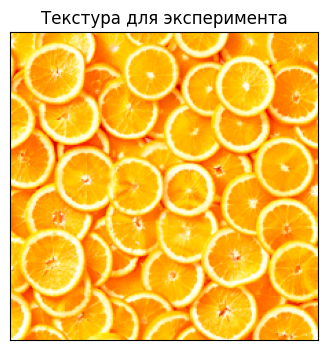

In [4]:
plt.figure(figsize=(4, 4))

plt.imshow(work_img.permute(1, 2, 0))

plt.title('Текстура для эксперимента')
plt.xticks([])
plt.yticks([])
plt.show()

In [15]:
vgg19 = models.vgg19(pretrained=True)
feature_extractor = vgg19.features.to(device).eval()
feature_extractor

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (17): ReLU(inplace=True)
  (18): MaxPoo

Первоначально я написал реализацию функции генерации текстуры с оптимизатором Adam, однако результаты были не очень хорошие: на генерируемых текстурах находились темные пятна и много шума. Так что по совету из соответствующей статьи я переписал с оптимизатором L-BFGS. С точки зрения теории он мне неизвестен. Функция с ним за меньшее время стала выдавать изображение лучшего качества.

In [16]:
# Прошлая реализация с Adam

# def generate_texture(
#         source_img : torch.tensor,
#         weights_losses : dict,
#         learning_rate : float = 1,
#         steps : int = 1000,
#         device : str = 'cpu'
# ):
#     # Инициализируем шумом итоговое изображение
#     x = torch.randn(source_img.shape, requires_grad=True, device=device)

#     # Инициализируем оптимизатор нашего изображения
#     optimizer = optim.Adam([x], lr=learning_rate)
#     sheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor = 0.8)

#     # Находим, до какого слоя будем прогонять итоговое изображение
#     # Будем подразумевать, что если вес указан, то он ненулевой, т.к.
#     # по умолчанию неуказанный вес нулевой
#     indexes_compute = {i : int(i in weights_losses.keys()) for i in range(len(feature_extractor))}

#     last_layer_id = max(weights_losses.keys())
#     part_model = feature_extractor[:last_layer_id + 1]

#     # Находим матрицы Грама для исходной текстуры
#     source_corrs = []

#     with torch.no_grad():
#         prev = source_img.clone().to(device)
#         output = torch.tensor([])

#         for id in range(last_layer_id + 1):
#             prev = part_model[id](prev)

#             if indexes_compute[id] == 1:
#                 output = prev.clone().flatten(start_dim = -2)
#                 source_corrs.append(output @ output.T)

#     torch.cuda.empty_cache()

#     x_corrs = [torch.tensor([]) for _ in range(len(source_corrs))]

#     # Теперь делаем шаги градиента
#     for i in range(steps):
#         prev = x.clone()

#         corrs_id = 0
#         for id in range(last_layer_id + 1):
#                 prev = part_model[id](prev)

#                 if indexes_compute[id] == 1:
#                     output = prev.flatten(start_dim=-2)
#                     x_corrs[corrs_id] = output @ output.T
#                     corrs_id += 1

#         loss = 0
#         corrs_id = 0

#         for id in range(last_layer_id + 1):
#             if indexes_compute[id] == 1:
#                 loss += weights_losses[id] * ((source_corrs[corrs_id] - x_corrs[corrs_id])**2).mean()
#                 corrs_id += 1

#         # Логируем лосс
#         print(f'Шаг {i}, loss = {loss}, lr = {sheduler.get_last_lr()}')

#         loss.backward()

#         optimizer.step()
#         sheduler.step(loss)

#         optimizer.zero_grad()

#     return x


def generate_texture_lbfgs(
        source_img : torch.tensor,
        weights_losses : dict,
        learning_rate : float = 1,
        steps : int = 1000,
        device : str = 'cpu'
):
    # Инициализируем шумом итоговое изображение
    x = torch.randn(source_img.shape, requires_grad=True, device=device)

    # Инициализируем оптимизатор нашего изображения
    optimizer = optim.LBFGS([x],
                            lr=learning_rate,
                            line_search_fn='strong_wolfe'
                            )

    # Находим, до какого слоя будем прогонять итоговое изображение
    # Будем подразумевать, что если вес указан, то он ненулевой, т.к.
    # по умолчанию неуказанный вес нулевой
    indexes_compute = {i : int(i in weights_losses.keys()) for i in range(len(feature_extractor))}

    last_layer_id = max(weights_losses.keys())
    part_model = feature_extractor[:last_layer_id + 1]

    # Находим матрицы Грама для исходной текстуры
    source_corrs = []

    with torch.no_grad():
        prev = source_img.clone().to(device)
        output = torch.tensor([])

        for id in range(last_layer_id + 1):
            prev = part_model[id](prev)

            if indexes_compute[id] == 1:
                output = prev.flatten(start_dim = -2)
                source_corrs.append(output @ output.T)

    torch.cuda.empty_cache()

    x_corrs = [torch.tensor([]) for _ in range(len(source_corrs))]

    # Теперь делаем шаги градиента
    for i in range(steps):

        def closure():
                optimizer.zero_grad()

                prev = x.clone()

                corrs_id = 0
                for id in range(last_layer_id + 1):
                        prev = part_model[id](prev)

                        if indexes_compute[id] == 1:
                            output = prev.clone().flatten(start_dim=-2)
                            x_corrs[corrs_id] = torch.mm(output, output.t())
                            corrs_id += 1

                loss = 0
                corrs_id = 0

                for id in range(last_layer_id + 1):
                    if indexes_compute[id] == 1:
                        loss += weights_losses[id] * ((source_corrs[corrs_id] - x_corrs[corrs_id])**2).mean()
                        corrs_id += 1

                loss.backward()
                return loss

        loss = optimizer.step(closure)

        # Логируем лосс
        print(f'Шаг {i}, loss = {loss}')

    return x


Теперь проверим, что выйдет при учете разного числа слоев. Будем сначала набирать сверточные слои с разной глубины. Посмотрим на те картинки, что получаются. Найдем наилучший вариант, учитывая качество текстуры и скорость генерации.

In [ ]:
def plot_result(res, layer_name):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(res.permute(1, 2, 0).detach().cpu())
    axes[0].set_xticks([])
    axes[0].set_yticks([])
    axes[0].set_title(layer_name)

    axes[1].imshow(work_img.permute(1, 2, 0).detach().cpu())
    axes[1].set_xticks([])
    axes[1].set_yticks([])
    axes[1].set_title('Исходная текстура')

    plt.suptitle('Генерация текстуры по примеру')

    plt.show()

Шаг 0, loss = 8885076992.0
Шаг 1, loss = 139937056.0
Шаг 2, loss = 5748756.0
Шаг 3, loss = 1068312.5
Шаг 4, loss = 282004.4375
Шаг 5, loss = 106359.0078125
Шаг 6, loss = 43943.0390625
Шаг 7, loss = 23513.4140625
Шаг 8, loss = 13136.5
Шаг 9, loss = 7851.60400390625
Шаг 10, loss = 4802.25
Шаг 11, loss = 3219.15869140625
Шаг 12, loss = 2193.292724609375
Шаг 13, loss = 1619.09423828125
Шаг 14, loss = 1166.2996826171875
Шаг 15, loss = 826.2578125
Шаг 16, loss = 602.7371826171875
Шаг 17, loss = 442.5948791503906
Шаг 18, loss = 345.58087158203125
Шаг 19, loss = 262.320068359375
Шаг 20, loss = 203.4193878173828
Шаг 21, loss = 160.29969787597656
Шаг 22, loss = 123.99014282226562
Шаг 23, loss = 96.3476333618164
Шаг 24, loss = 76.13624572753906
Шаг 25, loss = 60.46112823486328
Шаг 26, loss = 48.468528747558594
Шаг 27, loss = 39.7942008972168
Шаг 28, loss = 32.39696502685547
Шаг 29, loss = 26.8799991607666
Шаг 30, loss = 22.536109924316406
Шаг 31, loss = 19.26370620727539
Шаг 32, loss = 16.4941349

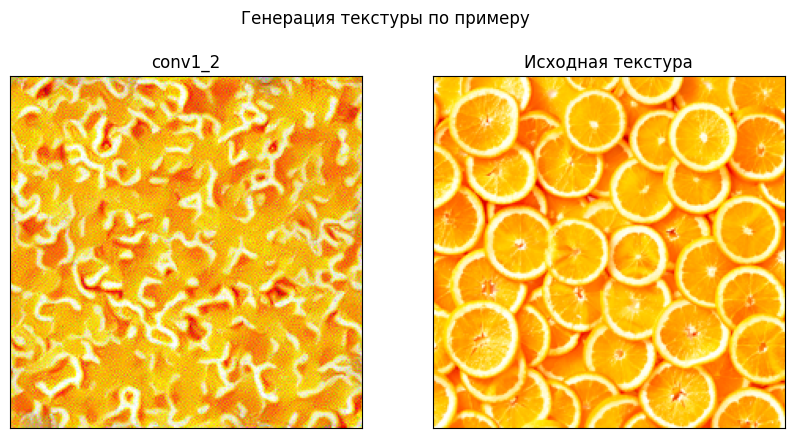

In [ ]:
results = {}

weights = {3 : 0.5} # conv1_2
results['conv1_2'] = denormalization(generate_texture_lbfgs(normalized_img, weights, 1, 50, device))

plot_result(results['conv1_2'], 'conv1_2')

Пока результат далек от той же текстуры. Кроме того, поверх есть лишний шум. Посмотрим на следующие генерации.

Шаг 0, loss = 6340135936.0
Шаг 1, loss = 225518928.0
Шаг 2, loss = 27729344.0
Шаг 3, loss = 6975578.0
Шаг 4, loss = 2572026.0
Шаг 5, loss = 1252043.75
Шаг 6, loss = 686518.75
Шаг 7, loss = 398727.25
Шаг 8, loss = 252644.578125
Шаг 9, loss = 163911.921875
Шаг 10, loss = 113690.25
Шаг 11, loss = 79675.625
Шаг 12, loss = 56575.3125
Шаг 13, loss = 42260.5546875
Шаг 14, loss = 31599.037109375
Шаг 15, loss = 24256.671875
Шаг 16, loss = 19169.37109375
Шаг 17, loss = 15285.482421875
Шаг 18, loss = 12377.107421875
Шаг 19, loss = 10059.7177734375
Шаг 20, loss = 8352.083984375
Шаг 21, loss = 6927.888671875
Шаг 22, loss = 5799.8642578125
Шаг 23, loss = 4959.732421875
Шаг 24, loss = 4210.37158203125
Шаг 25, loss = 3573.859619140625
Шаг 26, loss = 3056.28466796875
Шаг 27, loss = 2625.9072265625
Шаг 28, loss = 2294.52978515625
Шаг 29, loss = 1989.69873046875
Шаг 30, loss = 1743.92626953125
Шаг 31, loss = 1533.5421142578125
Шаг 32, loss = 1350.167236328125
Шаг 33, loss = 1197.1258544921875
Шаг 34, los

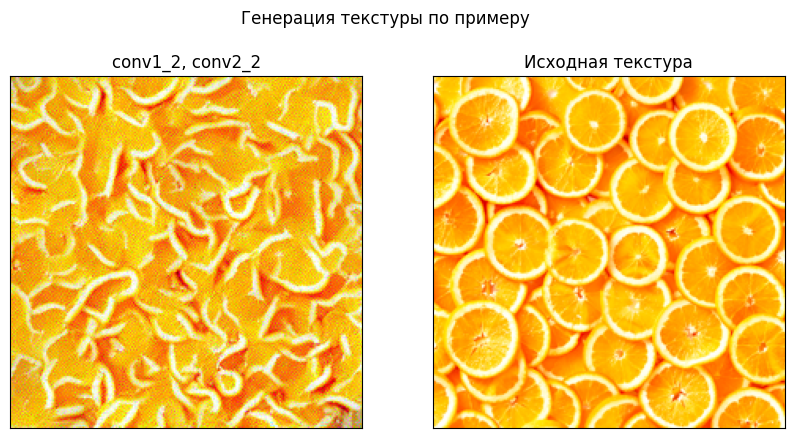

In [ ]:
weights = {3 : 0.25, 8 : 0.25} # conv1_2, conv2_2
results['conv1_2, conv2_2'] = denormalization(generate_texture_lbfgs(normalized_img, weights, 1, 50, device))

plot_result(results['conv1_2, conv2_2'], 'conv1_2, conv2_2')

Шаг 0, loss = 2657554432.0
Шаг 1, loss = 114007080.0
Шаг 2, loss = 19063576.0
Шаг 3, loss = 4912798.0
Шаг 4, loss = 2092880.5
Шаг 5, loss = 1163285.625
Шаг 6, loss = 737854.9375
Шаг 7, loss = 507971.09375
Шаг 8, loss = 384211.84375
Шаг 9, loss = 307401.75
Шаг 10, loss = 252150.0
Шаг 11, loss = 217300.09375
Шаг 12, loss = 189672.28125
Шаг 13, loss = 169326.21875
Шаг 14, loss = 152828.71875
Шаг 15, loss = 140346.921875
Шаг 16, loss = 129988.3046875
Шаг 17, loss = 121970.8203125
Шаг 18, loss = 115023.5234375
Шаг 19, loss = 109400.53125
Шаг 20, loss = 104462.765625
Шаг 21, loss = 99889.3125
Шаг 22, loss = 96103.0625
Шаг 23, loss = 92881.8203125
Шаг 24, loss = 89987.109375
Шаг 25, loss = 87412.5625
Шаг 26, loss = 84966.1015625
Шаг 27, loss = 82853.265625
Шаг 28, loss = 80857.1875
Шаг 29, loss = 79082.328125
Шаг 30, loss = 77439.8828125
Шаг 31, loss = 75872.1953125
Шаг 32, loss = 74389.421875
Шаг 33, loss = 73049.6484375
Шаг 34, loss = 71790.9296875
Шаг 35, loss = 70587.8828125
Шаг 36, loss 

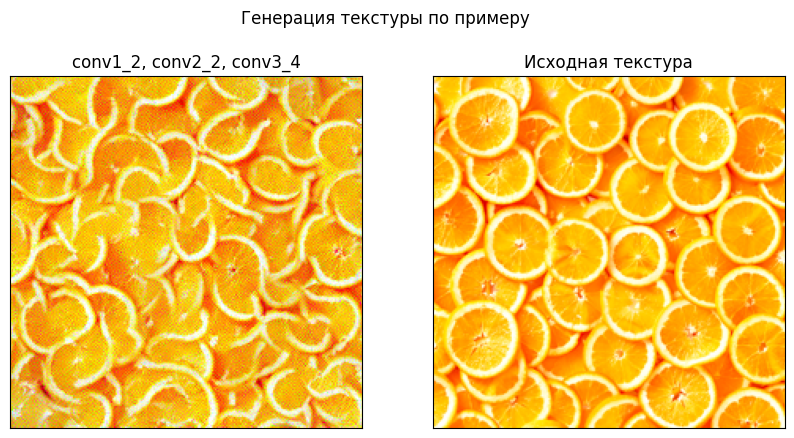

In [ ]:
weights = {3 : 0.1, 8 : 0.1, 17 : 0.1} # conv1_2, conv2_2, conv3_4
results['conv1_2, conv2_2, conv3_4'] = (denormalization(generate_texture_lbfgs(normalized_img, weights, 1, 50, device)))

plot_result(results['conv1_2, conv2_2, conv3_4'], 'conv1_2, conv2_2, conv3_4')

Эта генерация уже напоминает исходную текстуру, однако, содержащую скорее дольки апельсинов, нежели целые круги. Посмотрим на следующие.

Шаг 0, loss = 2663564800.0
Шаг 1, loss = 106514904.0
Шаг 2, loss = 16254369.0
Шаг 3, loss = 3937597.25
Шаг 4, loss = 1890593.5
Шаг 5, loss = 1058828.0
Шаг 6, loss = 695247.625
Шаг 7, loss = 490592.5
Шаг 8, loss = 384105.1875
Шаг 9, loss = 309730.84375
Шаг 10, loss = 261074.328125
Шаг 11, loss = 224891.78125
Шаг 12, loss = 200025.453125
Шаг 13, loss = 181032.515625
Шаг 14, loss = 165855.015625
Шаг 15, loss = 153453.5
Шаг 16, loss = 143370.890625
Шаг 17, loss = 135130.25
Шаг 18, loss = 128021.5546875
Шаг 19, loss = 121639.2734375
Шаг 20, loss = 116247.265625
Шаг 21, loss = 111731.171875
Шаг 22, loss = 107642.0703125
Шаг 23, loss = 104069.125
Шаг 24, loss = 101128.7734375
Шаг 25, loss = 98186.859375
Шаг 26, loss = 95555.3359375
Шаг 27, loss = 93313.2421875
Шаг 28, loss = 91183.9453125
Шаг 29, loss = 89256.625
Шаг 30, loss = 87368.6875
Шаг 31, loss = 85726.0546875
Шаг 32, loss = 84183.046875
Шаг 33, loss = 82740.765625
Шаг 34, loss = 81291.015625
Шаг 35, loss = 79995.4921875
Шаг 36, loss =

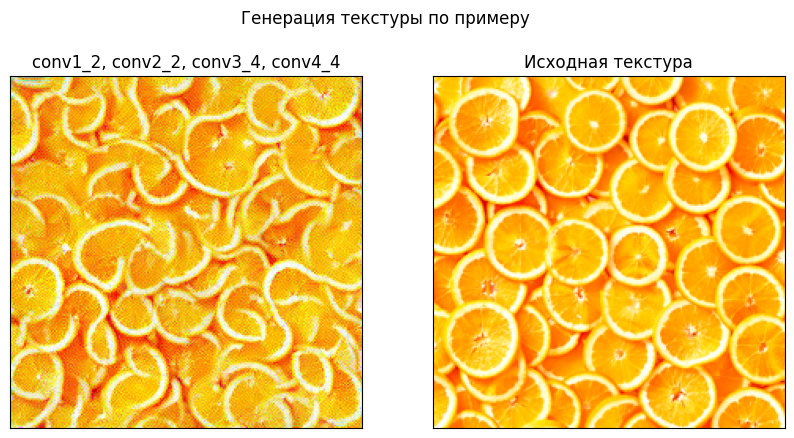

In [ ]:
weights = {3 : 0.1, 8 : 0.1, 17 : 0.1, 26 : 0.1} # conv1_2, conv2_2, conv3_4, conv4_4
results['conv1_2, conv2_2, conv3_4, conv4_4'] = denormalization(generate_texture_lbfgs(normalized_img, weights, 1, 175, device))

plot_result(results['conv1_2, conv2_2, conv3_4, conv4_4'], 'conv1_2, conv2_2, conv3_4, conv4_4')

Шаг 0, loss = 1333606272.0
Шаг 1, loss = 65202244.0
Шаг 2, loss = 11213551.0
Шаг 3, loss = 2453861.5
Шаг 4, loss = 1020362.625
Шаг 5, loss = 581821.5
Шаг 6, loss = 366840.6875
Шаг 7, loss = 257673.75
Шаг 8, loss = 192828.03125
Шаг 9, loss = 155474.5625
Шаг 10, loss = 128608.296875
Шаг 11, loss = 110925.3125
Шаг 12, loss = 97559.46875
Шаг 13, loss = 87685.4140625
Шаг 14, loss = 79542.390625
Шаг 15, loss = 73154.15625
Шаг 16, loss = 68170.640625
Шаг 17, loss = 63925.48828125
Шаг 18, loss = 60493.6015625
Шаг 19, loss = 57671.91015625
Шаг 20, loss = 55230.7265625
Шаг 21, loss = 53025.87890625
Шаг 22, loss = 51150.09765625
Шаг 23, loss = 49456.55859375
Шаг 24, loss = 47884.140625
Шаг 25, loss = 46527.08984375
Шаг 26, loss = 45315.87890625
Шаг 27, loss = 44194.51171875
Шаг 28, loss = 43238.41015625
Шаг 29, loss = 42292.75
Шаг 30, loss = 41434.3203125
Шаг 31, loss = 40696.15234375
Шаг 32, loss = 39959.05859375
Шаг 33, loss = 39310.10546875
Шаг 34, loss = 38708.3046875
Шаг 35, loss = 38119.742

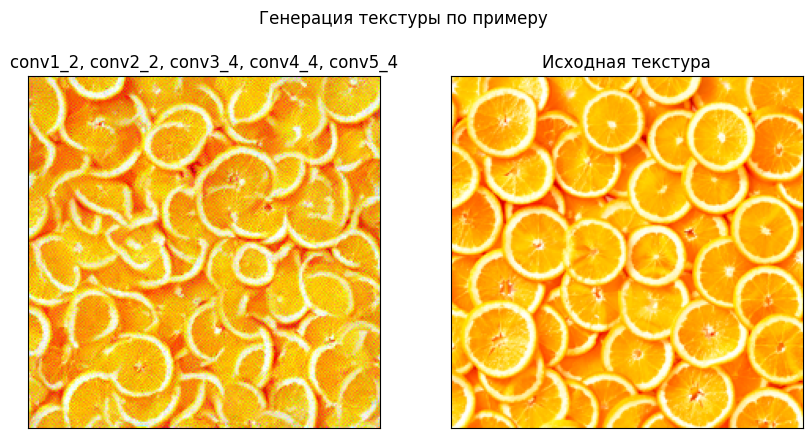

In [ ]:
weights = {3 : 0.05, 8 : 0.05, 17 : 0.05, 26 : 0.05, 29 : 0.05} # conv1_2, conv2_2, conv3_4, conv4_4, conv5_4
results['conv1_2, conv2_2, conv3_4, conv4_4, conv5_4'] = denormalization(generate_texture_lbfgs(normalized_img, weights, 1, 75, device))

plot_result(results['conv1_2, conv2_2, conv3_4, conv4_4, conv5_4'], 'conv1_2, conv2_2, conv3_4, conv4_4, conv5_4')

Теперь посмотрим на все генерации вместе, чтобы оценить разницу в генерациях.

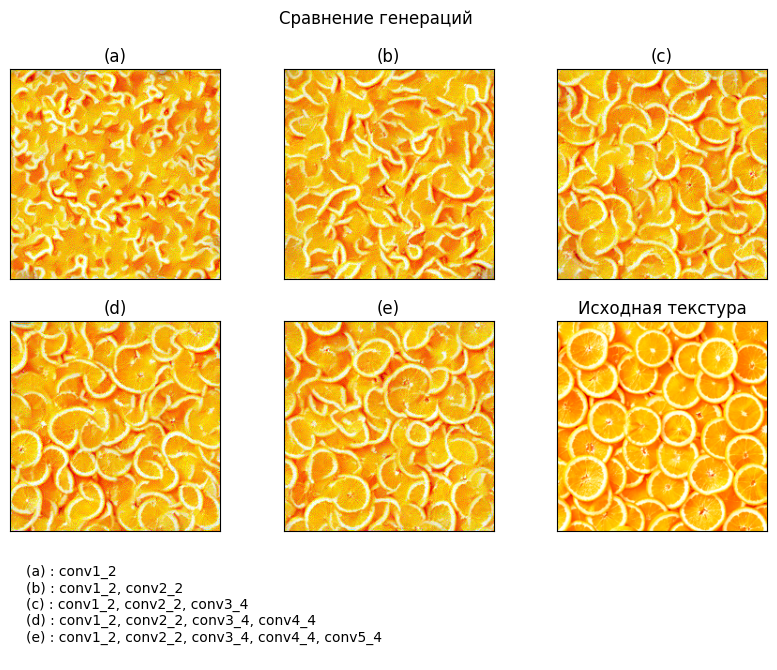

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
axes = axes.flatten()

for i in range(5):
    axes[i].imshow(results[list(results.keys())[i]].permute(1, 2, 0).detach().cpu())
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_title(f'({chr(ord('a') + i)})')

axes[5].imshow(work_img.permute(1, 2, 0))
axes[5].set_xticks([])
axes[5].set_yticks([])
axes[5].set_title('Исходная текстура')

label = ''
for i in range(5):
    label += f'({chr(ord('a') + i)}) : {list(results.keys())[i]}\n'

plt.figtext(0.15, -0.1, label)
plt.suptitle('Сравнение генераций')
plt.show()

Никакая из генераций не смогла достаточно точно приблизиться к текстуре. На текстурах почти отсутствуют целые части апельсина, то есть круги. Однако, что-то подобное на них можно разглядеть в генерациях $(c)$, $(d)$, $(e)$. Таким образом, генерации $(a)$ и $(b)$ далеки от исходной текстуры. В основном, на них отражается маленький паттерн исходной текстуры. Оно и понятно, ведь сеть на неглубоких слоях не очень сильно обощает информацию изображения (маленький, так называемый, receptive field)

Сложно сказать, что генерация $(e)$ заметно лучше генерации $(d)$. Кажется, что на генерации $(e)$ побольше почти целых кругов, к чему мы и стремимся.

Продолжим исследовать модель. Посмотрим на генерации, если брать только один сверточный слой на каждой глубине.

In [ ]:
# Для более стабильный вычислений беру с множителем 0.1
list_weights = [{1 : 0.1}, {6 : 0.1}, {10 : 0.1}, {19 : 0.1}, {28 : 0.1}]

for i in range(5):
    results[f'conv{i + 1}_1'] = denormalization(generate_texture_lbfgs(normalized_img, list_weights[i], 1, 75, device))

    print(f'- Сгенерирована текстура с conv{i + 1}_1')

Шаг 0, loss = 67413472.0
Шаг 1, loss = 468922.09375
Шаг 2, loss = 23509.40625
Шаг 3, loss = 3399.67578125
Шаг 4, loss = 883.9571533203125
Шаг 5, loss = 321.8246765136719
Шаг 6, loss = 129.7427215576172
Шаг 7, loss = 71.40194702148438
Шаг 8, loss = 43.68032455444336
Шаг 9, loss = 28.105478286743164
Шаг 10, loss = 18.754011154174805
Шаг 11, loss = 12.555811882019043
Шаг 12, loss = 9.061141014099121
Шаг 13, loss = 6.967483043670654
Шаг 14, loss = 5.291636943817139
Шаг 15, loss = 4.118537902832031
Шаг 16, loss = 3.3190534114837646
Шаг 17, loss = 2.68149733543396
Шаг 18, loss = 2.182006359100342
Шаг 19, loss = 1.808449149131775
Шаг 20, loss = 1.4922761917114258
Шаг 21, loss = 1.2011066675186157
Шаг 22, loss = 1.0084089040756226
Шаг 23, loss = 0.8670405745506287
Шаг 24, loss = 0.7481482625007629
Шаг 25, loss = 0.643091082572937
Шаг 26, loss = 0.5538116097450256
Шаг 27, loss = 0.48001909255981445
Шаг 28, loss = 0.41768303513526917
Шаг 29, loss = 0.36244794726371765
Шаг 30, loss = 0.3185876309

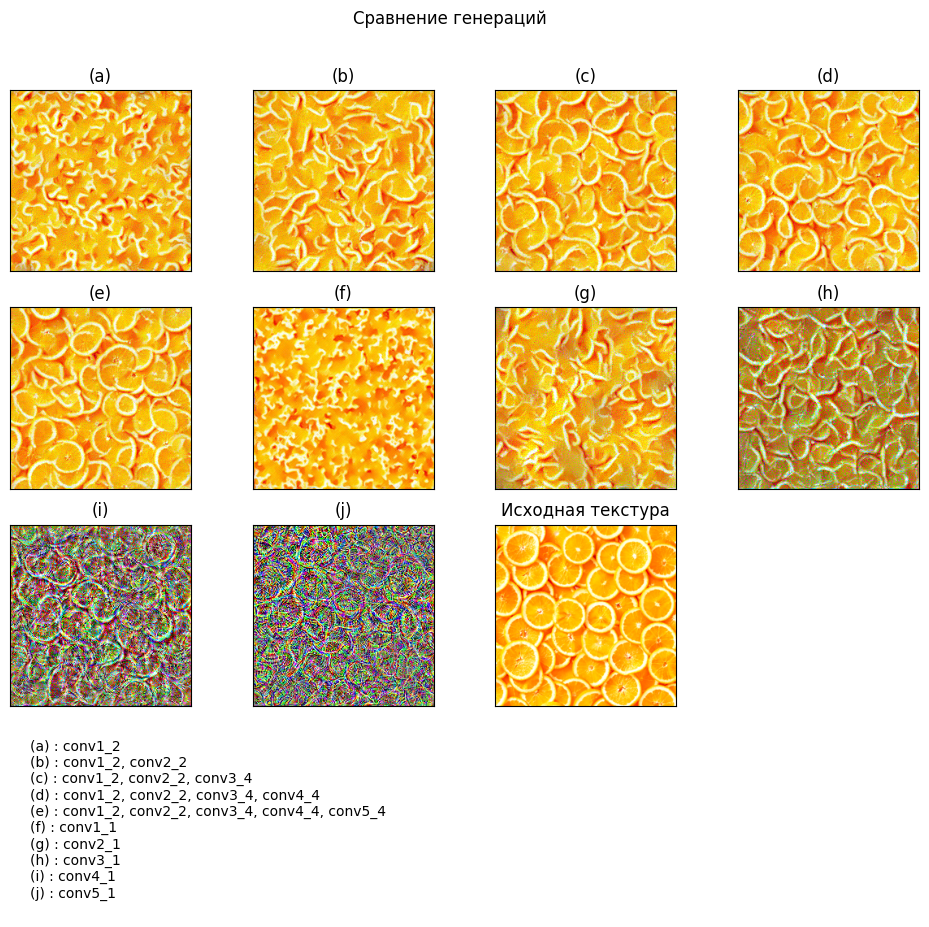

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
axes = axes.flatten()

for i in range(len(results)):
    axes[i].imshow(results[list(results.keys())[i]].permute(1, 2, 0).detach().cpu())
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_title(f'({chr(ord('a') + i)})')

axes[10].imshow(work_img.permute(1, 2, 0))
axes[10].set_xticks([])
axes[10].set_yticks([])
axes[10].set_title('Исходная текстура')

axes[11].set_visible(False)

label = ''
for i in range(len(results)):
    label += f'({chr(ord('a') + i)}) : {list(results.keys())[i]}\n'


plt.figtext(0.15, -0.15, label)
plt.suptitle('Сравнение генераций')
plt.show()

Видим, что изображения, сделанные по одному слою на глубине, очень зашумленные и далеки от текстуры. Они теряют цвет, однако сохраняют паттерн. Попробуем скомбинировать некоторые слои. Например, кажется, что если к генерации $(i)$ Добавить цвета, то она станет хорошо напоминать текстуру.

In [ ]:
list_weights = [{1 : 0.1, 20 : 0.1}, {1 : 0.1, 6 : 0.1, 20 : 0.1}, {1 : 0.1, 6 : 0.1, 11 : 0.1, 20 : 0.1}]
list_names = ['conv1_1, conv4_1', 'conv1_1, conv2_1, conv4_1', 'conv1_1, conv2_1, conv3_1, conv4_1']

for i in range(len(list_weights)):
    results[list_names[i]] = denormalization(generate_texture_lbfgs(normalized_img, list_weights[i], 1, 75, device))

    print(f'- Сгенерирована текстура с {list_names[i]}')

Шаг 0, loss = 75744928.0
Шаг 1, loss = 2418187.75
Шаг 2, loss = 514729.75
Шаг 3, loss = 236280.03125
Шаг 4, loss = 139212.984375
Шаг 5, loss = 100047.6796875
Шаг 6, loss = 76720.1875
Шаг 7, loss = 62784.4375
Шаг 8, loss = 53314.1484375
Шаг 9, loss = 47138.26171875
Шаг 10, loss = 42507.7578125
Шаг 11, loss = 39091.50390625
Шаг 12, loss = 36439.5078125
Шаг 13, loss = 34199.98828125
Шаг 14, loss = 32532.064453125
Шаг 15, loss = 31076.470703125
Шаг 16, loss = 29778.46484375
Шаг 17, loss = 28694.837890625
Шаг 18, loss = 27712.49609375
Шаг 19, loss = 26847.021484375
Шаг 20, loss = 26048.748046875
Шаг 21, loss = 25364.7265625
Шаг 22, loss = 24789.2265625
Шаг 23, loss = 24235.97265625
Шаг 24, loss = 23778.99609375
Шаг 25, loss = 23331.69140625
Шаг 26, loss = 22960.35546875
Шаг 27, loss = 22622.568359375
Шаг 28, loss = 22283.87109375
Шаг 29, loss = 21992.6015625
Шаг 30, loss = 21716.51953125
Шаг 31, loss = 21463.0703125
Шаг 32, loss = 21229.203125
Шаг 33, loss = 21019.443359375
Шаг 34, loss = 2

In [ ]:
results['conv1_1, conv2_1, conv3_1, conv4_1, conv5_1'] = \
    denormalization(generate_texture_lbfgs(normalized_img, {1 : 0.1, 6 : 0.1, 11 : 0.1, 20 : 0.1, 29 : 0.1}, 1, 75, device))

Шаг 0, loss = 778709760.0
Шаг 1, loss = 48409076.0
Шаг 2, loss = 7985252.0
Шаг 3, loss = 1990807.625
Шаг 4, loss = 906622.25
Шаг 5, loss = 545853.1875
Шаг 6, loss = 380046.5625
Шаг 7, loss = 275636.4375
Шаг 8, loss = 217572.671875
Шаг 9, loss = 182790.84375
Шаг 10, loss = 156571.453125
Шаг 11, loss = 138747.90625
Шаг 12, loss = 124864.625
Шаг 13, loss = 114104.25
Шаг 14, loss = 106364.9453125
Шаг 15, loss = 99522.2109375
Шаг 16, loss = 94044.1484375
Шаг 17, loss = 89342.515625
Шаг 18, loss = 85462.2109375
Шаг 19, loss = 82156.40625
Шаг 20, loss = 79231.8359375
Шаг 21, loss = 76710.7578125
Шаг 22, loss = 74499.828125
Шаг 23, loss = 72552.359375
Шаг 24, loss = 70770.34375
Шаг 25, loss = 69153.3359375
Шаг 26, loss = 67685.171875
Шаг 27, loss = 66415.421875
Шаг 28, loss = 65207.0078125
Шаг 29, loss = 64069.67578125
Шаг 30, loss = 63020.6875
Шаг 31, loss = 62035.6875
Шаг 32, loss = 61201.2734375
Шаг 33, loss = 60357.32421875
Шаг 34, loss = 59627.171875
Шаг 35, loss = 58975.125
Шаг 36, loss 

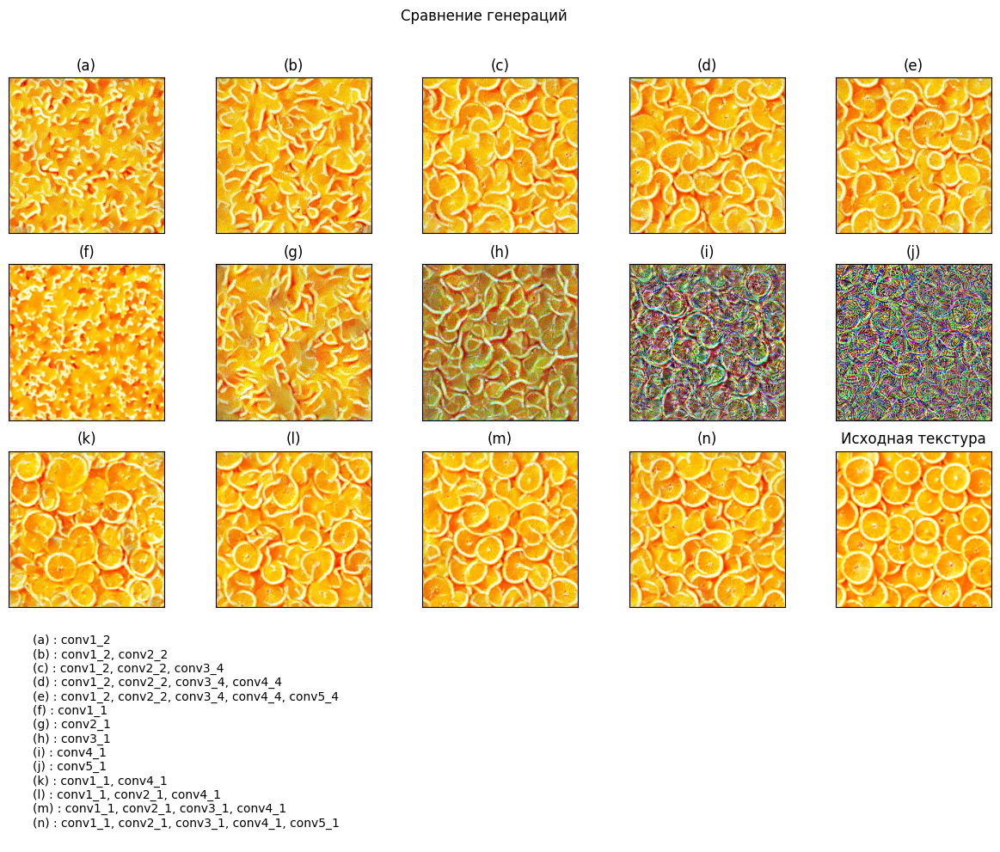

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
axes = axes.flatten()

for i in range(len(results) - 1):
    axes[i].imshow(results[list(results.keys())[i]].permute(1, 2, 0).detach().cpu())
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_title(f'({chr(ord('a') + i)})')

axes[14].imshow(work_img.permute(1, 2, 0))
axes[14].set_xticks([])
axes[14].set_yticks([])
axes[14].set_title('Исходная текстура')

label = ''
for i in range(len(results) - 1):
    label += f'({chr(ord('a') + i)}) : {list(results.keys())[i]}\n'

plt.figtext(0.15, -0.23, label)
plt.suptitle('Сравнение генераций')
plt.show()

Текстура $(m)$ больше всех прочих напоминает исходную. Посмотрим на нее ближе.

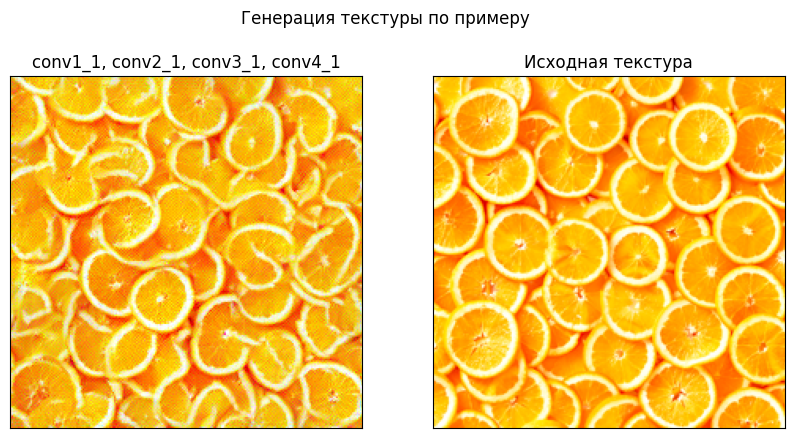

In [ ]:
plot_result(results['conv1_1, conv2_1, conv3_1, conv4_1'], 'conv1_1, conv2_1, conv3_1, conv4_1')

Эта текстура действительно очень близка к исходной. В основном мы видим круги из апельсинов, как и должно быть. Однако, они не очень ровные. Попробуем взять все активации и пулинги до 4-го пулинга. Сравним с текстурой $(m)$.

In [ ]:
last_layer = 27
weights = {i : 0.01 for i in range(last_layer + 1) if str(feature_extractor[i])[:4] != 'Conv'}
results['all activations before pool4'] = denormalization(generate_texture_lbfgs(normalized_img, weights, 1, 50, device))

Шаг 0, loss = 624879552.0
Шаг 1, loss = 37585080.0
Шаг 2, loss = 9709455.0
Шаг 3, loss = 2151436.75
Шаг 4, loss = 815632.1875
Шаг 5, loss = 482905.84375
Шаг 6, loss = 335126.8125
Шаг 7, loss = 252640.828125
Шаг 8, loss = 202713.53125
Шаг 9, loss = 169888.6875
Шаг 10, loss = 149396.53125
Шаг 11, loss = 134510.046875
Шаг 12, loss = 122755.1484375
Шаг 13, loss = 113872.1328125
Шаг 14, loss = 106821.625
Шаг 15, loss = 100879.046875
Шаг 16, loss = 95918.015625
Шаг 17, loss = 91583.9609375
Шаг 18, loss = 87927.0078125
Шаг 19, loss = 84768.765625
Шаг 20, loss = 82220.734375
Шаг 21, loss = 79914.1328125
Шаг 22, loss = 77814.7421875
Шаг 23, loss = 76039.09375
Шаг 24, loss = 74301.734375
Шаг 25, loss = 72864.9296875
Шаг 26, loss = 71522.9765625
Шаг 27, loss = 70264.28125
Шаг 28, loss = 69109.8046875
Шаг 29, loss = 68086.5703125
Шаг 30, loss = 67151.875
Шаг 31, loss = 66226.0703125
Шаг 32, loss = 65455.37890625
Шаг 33, loss = 64722.90625
Шаг 34, loss = 64037.41015625
Шаг 35, loss = 63380.0703125


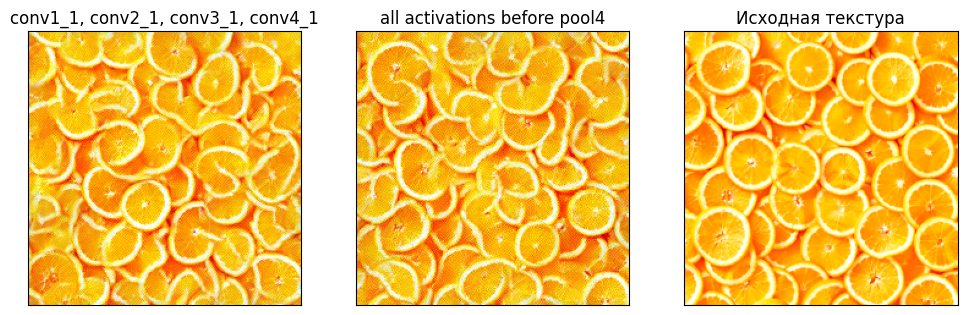

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6))

axes[0].imshow(results['conv1_1, conv2_1, conv3_1, conv4_1'].permute(1, 2, 0).detach().cpu())
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].set_title('conv1_1, conv2_1, conv3_1, conv4_1')

axes[1].imshow(results['all activations before pool4'].permute(1, 2, 0).detach().cpu())
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_title('all activations before pool4')

axes[2].imshow(work_img.permute(1, 2, 0).detach().cpu())
axes[2].set_xticks([])
axes[2].set_yticks([])
axes[2].set_title('Исходная текстура')

plt.show()

Качество этих двух сгенерированных текстур неотличимо. Как видим, приблизиться достаточно точно к исходной текстуре не удалось. Возможно, так выходит из-за сложности исходной текстуры. Далее посмотрим на примере других текстур для некоторых наборов весов. Выявим наиболее подходящий набор весов для получения реалистичных текстур в большинстве случаев. После попробуем на основе этого найти оптимальный по вычислениям.

Рассмотрим текстуры, где у модели больше шансов на генерацию хорошей текстуры: текстура травы и текстура камней. Дополнительно, так как предпосылка этой работы есть перенос стиля, рассмотрим текстуру, сгенерированную по картине Ван Гога "Звездная ночь".

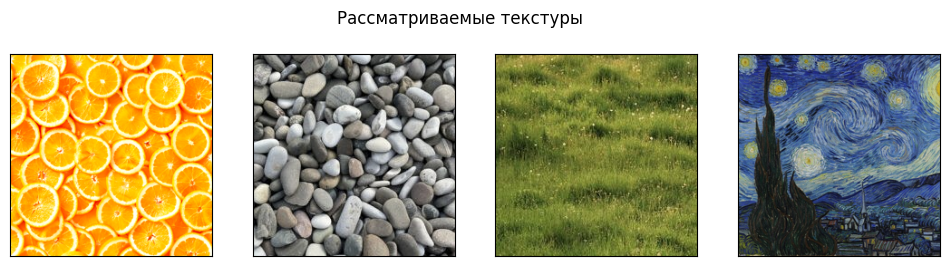

In [6]:
rock = Image.open('texture_src/rock_texture.jpg').convert('RGB')
grass = Image.open('texture_src/grass_texture.jpg').convert('RGB')
art = Image.open('texture_src/art_texture.jpg').convert('RGB')

rock_texture = transforms.ToTensor()(rock.resize((224, 224)))
grass_texture = transforms.ToTensor()(grass.resize((224, 224)))
art_texture = transforms.ToTensor()(art.resize((224, 224)))

textures = [work_img, rock_texture, grass_texture, art_texture]

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i in range(4):
    axes[i].imshow(textures[i].permute(1, 2, 0))
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.suptitle('Рассматриваемые текстуры')
plt.show()

Посмотрим на генерации, основанные на всех слоях до $i$-го пулинга, включая сам пулинг (для i = 1, 2, 3, 4, 5).

In [ ]:
poolings_id = [i for i in range(len(feature_extractor)) if str(feature_extractor[i])[:3] == 'Max']
list_weights = [{j : 0.01 for j in range(poolings_id[i] + 1) if str(feature_extractor[j])[:4] != 'Conv'} for i in range(len(poolings_id))]

generations = []
for i in range(len(list_weights)):
    generations.append([])

    for image in textures:
        generations[-1].append(denormalization(generate_texture_lbfgs(normalization(image), list_weights[i], 1, 50, device=device)))
    print(f'-Сгенерированы текстуры для pool{i + 1}')

Шаг 0, loss = 358481344.0
Шаг 1, loss = 5231429.0
Шаг 2, loss = 167182.296875
Шаг 3, loss = 32673.326171875
Шаг 4, loss = 10313.388671875
Шаг 5, loss = 4519.72265625
Шаг 6, loss = 2170.004638671875
Шаг 7, loss = 1278.6226806640625
Шаг 8, loss = 798.8408203125
Шаг 9, loss = 507.535888671875
Шаг 10, loss = 336.7392883300781
Шаг 11, loss = 237.16102600097656
Шаг 12, loss = 177.14735412597656
Шаг 13, loss = 136.16653442382812
Шаг 14, loss = 108.65847778320312
Шаг 15, loss = 84.05768585205078
Шаг 16, loss = 68.4203109741211
Шаг 17, loss = 55.68852996826172
Шаг 18, loss = 46.7010498046875
Шаг 19, loss = 39.61625289916992
Шаг 20, loss = 33.878658294677734
Шаг 21, loss = 28.963037490844727
Шаг 22, loss = 25.30853271484375
Шаг 23, loss = 22.199230194091797
Шаг 24, loss = 19.753997802734375
Шаг 25, loss = 17.53995132446289
Шаг 26, loss = 15.368766784667969
Шаг 27, loss = 13.639256477355957
Шаг 28, loss = 12.326142311096191
Шаг 29, loss = 11.167264938354492
Шаг 30, loss = 10.152365684509277
Шаг 3

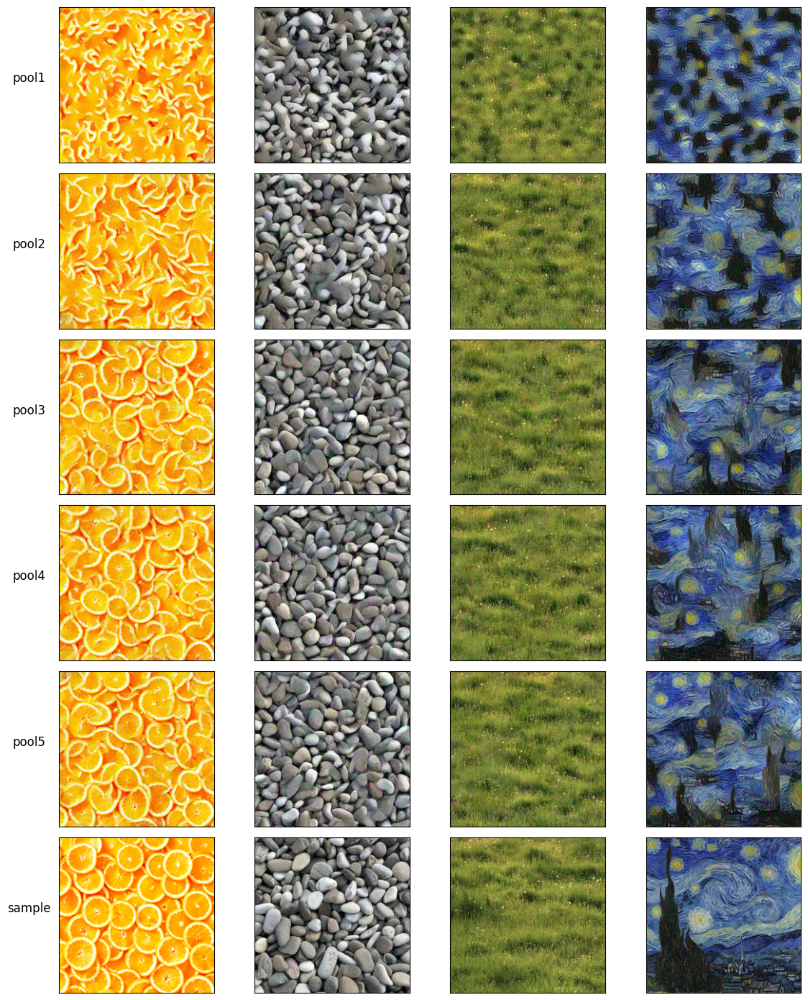

In [ ]:
fig, axes = plt.subplots(6, 4, figsize=(12, 14))

for i in range(5):
    for j in range(4):
        axes[i, j].imshow(generations[i][j].permute(1, 2, 0).detach().cpu())
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

        if j == 0:
            axes[i, j].set_ylabel(f'pool{i + 1}', rotation=0, labelpad=30, size='large')

for j in range(4):
    axes[5, j].imshow(textures[j].permute(1, 2, 0))
    axes[5, j].set_xticks([])
    axes[5, j].set_yticks([])

    if j == 0:
        axes[5, j].set_ylabel('sample', rotation=0, labelpad=30, size='large')

plt.tight_layout()
plt.show()

На других природных текстурах модель справилась гораздо лучше: генерации под надписями pool4 и pool5 для камней и травы выглядят почти идеально, их очень сложно отличить от оригинала, в особенности траву.

Генерации по картине Ван Гога получились довольно красивыми, действительно отражают стиль, что пригодится нам в алгоритме нейронного переноса стиля. Они также показывают, как синтез текстуры меняется с увеличением рассматриваемых слоев: сначала генерируемая текстура отражает маленький паттерн, а затем паттерн увеличивается в размерах и отражает больше элементов исходного изображения.

Все это показывает, что с некоторыми текстурами модель справляется очень хорошо.

Теперь про качество. Видим, что текстуры становятся достаточно близкими к оригиналу, начиная с pool3. Однако, на самом pool3 все еще встречаются недочеты в виде размытости объектов и нецелостности элементов (например, на текстуре апельсинов нет целых кругов). Качество pool4 уже такого не имеет. Одновременно с этим стоит отметить, что качество pool4 и pool5 сложно отличить.

Теперь сравним генерацию pool4 с генерацией, включающую лишь активации conv1_1, conv2_1, conv3_1, conv4_1, поскольку генерация на апельсинах дала хороший результат с такими слоями и считается быстрее. Сравним и по времени, и по качеству.

In [ ]:
weights_compare = [{1 : 0.01, 6 : 0.01, 11 : 0.01, 20 : 0.01}, {i : 0.01 for i in range(poolings_id[3] + 1)}]
generations_compare = []
time_compare = []

for i in range(2):
    generations_compare.append([])

    start_tm = time()
    for image in textures:
        generations_compare[-1].append(denormalization(generate_texture_lbfgs(normalization(image), weights, 1, 50, device)))

    end_tm = time()
    time_compare.append(end_tm - start_tm)

Шаг 0, loss = 624010176.0
Шаг 1, loss = 34578580.0
Шаг 2, loss = 8756279.0
Шаг 3, loss = 2148097.5
Шаг 4, loss = 827100.875
Шаг 5, loss = 487476.34375
Шаг 6, loss = 339641.375
Шаг 7, loss = 257492.0625
Шаг 8, loss = 207409.75
Шаг 9, loss = 173883.953125
Шаг 10, loss = 150830.578125
Шаг 11, loss = 134710.25
Шаг 12, loss = 122703.9765625
Шаг 13, loss = 114402.0390625
Шаг 14, loss = 107202.8515625
Шаг 15, loss = 101126.7265625
Шаг 16, loss = 96262.9609375
Шаг 17, loss = 92087.5234375
Шаг 18, loss = 88474.1796875
Шаг 19, loss = 85438.96875
Шаг 20, loss = 82955.046875
Шаг 21, loss = 80575.6015625
Шаг 22, loss = 78662.9609375
Шаг 23, loss = 76867.078125
Шаг 24, loss = 75319.1328125
Шаг 25, loss = 73806.1640625
Шаг 26, loss = 72463.1640625
Шаг 27, loss = 71363.6953125
Шаг 28, loss = 70206.4453125
Шаг 29, loss = 69179.3515625
Шаг 30, loss = 68240.5078125
Шаг 31, loss = 67368.03125
Шаг 32, loss = 66612.5546875
Шаг 33, loss = 65840.7578125
Шаг 34, loss = 65134.58203125
Шаг 35, loss = 64487.99218

In [ ]:
print(f'Время генерации по conv1_1, conv2_1, conv3_1, conv4_1 : {int(time_compare[0])}')
print(f'Время генерации по всем слоям до pool4 : {int(time_compare[1])}')

Время генерации по conv1_1, conv2_1, conv3_1, conv4_1 : 326
Время генерации по всем слоям до pool4 : 328


Видим, что различие во времени незначительное, хотя генерация по всем слоям до pool4 характеризуется большим числом слоев для прогона, а также большим числом матриц Грама. Возможно, на изображениях большего размера разница будет более существенной.

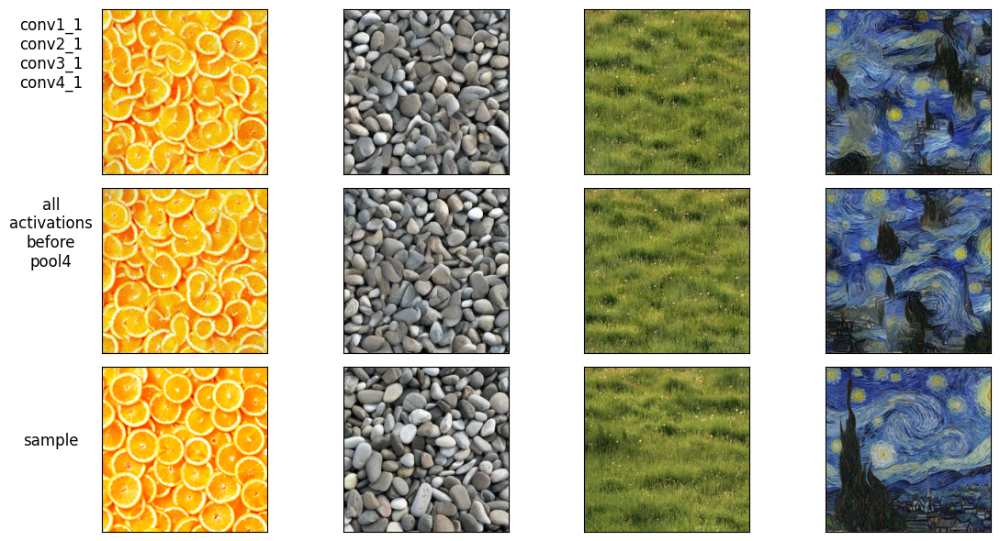

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(12, 6))

for i in range(2):
    for j in range(4):
        axes[i, j].imshow(generations_compare[i][j].permute(1, 2, 0).detach().cpu())
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

        if j == 0 and i == 0:
            axes[i, j].set_ylabel(f'conv1_1\nconv2_1\nconv3_1\nconv4_1', rotation=0, labelpad=40, size='large')
        if j == 0 and i == 1:
            axes[i, j].set_ylabel(f'all\nactivations\nbefore\npool4', rotation=0, labelpad=40, size='large')

for j in range(4):
    axes[2, j].imshow(textures[j].permute(1, 2, 0))
    axes[2, j].set_xticks([])
    axes[2, j].set_yticks([])

    if j == 0:
        axes[2, j].set_ylabel('sample', rotation=0, labelpad=40, size='large')

plt.tight_layout()
plt.show()

В качестве генерации различий также нет. Следовательно, для изображений размера 224 на 224 делаем вывод, что разница несущественна. Возможно, на изображениях большего размера будет разница во времени или качестве.

Следующий вопрос: масштабируется ли это? Виднеется 2 вопроса.

Первый - можно ли применить алгоритм для генерации изображения с такой же текстурой, но большего размера. Вопрос вполне естественный, ведь для этого синтез текстур и нужен. Мы хотим естественно как бы продолжить нашу картинку в разные стороны и применить ее так где-нибудь. Кажется, что проблемы в таком применении не возникает. Ничто не мешает нам взять генерируемую текстуру $\vec{x}$ в нужном разрешении. Далее, при прогоне по сети мы все равно получаем фиксированное число отфильтрованных изображений согласно архитектуре сети. Да, размер каждого выхода из слоя отличается от размера выхода из того же слоя исходной текстуры, но ведь мы приближаем именно матрицы Грама. Матрицы Грама будут одного и того же размера $N_l \times N_l$.

Второй - как алгоритм поведет себя на изображениях, размер которых отличен от 224 на 224. Здесь потребует провести несколько экспериментов и оценить результаты.

Разберемся с первым вопросом. Рассмотрим текстуру камней, что рассматривали выше. Прежде всего придется немного исправить нашу функцию генерации. Зафиксируем в ней сразу и веса слоев.

UPD : На данном этапе я столкнулся с проблемой. Генерируемая текстура камней большего размера была некачественной. На изображении были темные пятна, где виднелись лишь очертания камней. При этом увеличение числа шагов привело бы к более 5 минутам ожидания генерации, что мне не подходит.

На этом этапе я вспомнил, что моя генерация отличается от той, что в статье тем, что я использую ненормализованную версию модели VGG (под нормализацией имеется в виду нормализация весов таким образом, чтобы средняя активация фильтров каждого слоя равнялась $1$), а также тем, что лосс со слоя я не делю на $M_l^2$

Отсюда возникает желание проверить, как меняется генерация, когда изменяется формула лосса и когда изменяется модель описанными выше способами. Сравним время генераций для одинакового числа шагов и качество полученных текстур.

In [7]:
normalized_vgg = torch.load('normalized_vgg.pt', weights_only=False)
features = normalized_vgg.features.to(device).eval()

In [25]:
weights = {1 : 1, 6 : 1, 11 : 1, 20 : 1}

# Меняем лосс, модель - обычная VGG
def generate_texture_experiment(
        input_img : torch.tensor,
        weights_losses : dict,
        width : int,
        height : int,
        steps : int = 50,
        device : str = 'cpu',
        loss_mode: bool = False
):
    # Применяем нормализацию для сети VGG
    source_img = normalization(input_img)

    # Инициализируем шумом итоговое изображение
    x = torch.randn((input_img.shape[0], height, width), requires_grad=True, device=device)

    weights_losses = weights
    learning_rate = 1

    # Инициализируем оптимизатор нашего изображения
    optimizer = optim.LBFGS([x],
                            lr=learning_rate,
                            line_search_fn='strong_wolfe'
                            )

    # Находим, до какого слоя будем прогонять итоговое изображение
    # Будем подразумевать, что если вес указан, то он ненулевой, т.к.
    # по умолчанию неуказанный вес нулевой
    indexes_compute = {i : int(i in weights_losses.keys()) for i in range(len(feature_extractor))}

    last_layer_id = max(weights_losses.keys())
    part_model = feature_extractor[:last_layer_id + 1]

    # Находим матрицы Грама для исходной текстуры
    source_corrs = []

    with torch.no_grad():
        prev = source_img.clone().to(device)
        output = torch.tensor([])

        for id in range(last_layer_id + 1):
            prev = part_model[id](prev)

            if indexes_compute[id] == 1:
                output = prev.flatten(start_dim = -2)

                if loss_mode:
                    source_corrs.append(torch.mm(output, output.t()) / output.shape[1])
                else:
                    source_corrs.append(torch.mm(output, output.t()))

    torch.cuda.empty_cache()

    x_corrs = [torch.tensor([]) for _ in range(len(source_corrs))]

    # Теперь делаем шаги градиента
    for i in range(steps):

        def closure():
                optimizer.zero_grad()

                prev = x.clone()

                corrs_id = 0
                for id in range(last_layer_id + 1):
                        prev = part_model[id](prev)

                        if indexes_compute[id] == 1:
                            output = prev.clone().flatten(start_dim=-2)

                            if loss_mode:
                                x_corrs[corrs_id] = torch.mm(output, output.t()) / output.shape[1]
                            else:
                                x_corrs[corrs_id] = torch.mm(output, output.t())

                            corrs_id += 1

                loss = 0
                corrs_id = 0

                for id in range(last_layer_id + 1):
                    if indexes_compute[id] == 1:
                        loss += weights_losses[id] * ((source_corrs[corrs_id] - x_corrs[corrs_id])**2).mean()
                        corrs_id += 1

                loss.backward()
                return loss

        loss = optimizer.step(closure)

        # Логируем лосс
        print(f'Шаг {i}, loss = {loss}')

    return denormalization(x).detach().cpu()

# С нормализованной версией модели, лосс также изменен
def generate_texture_normalized(
        input_img : torch.tensor,
        weights_losses : dict,
        width : int,
        height : int,
        steps : int = 50,
        device : str = 'cpu'
):
    # Применяем нормализацию для сети VGG
    source_img = normalization(input_img)

    # Инициализируем шумом итоговое изображение
    x = torch.randn((input_img.shape[0], height, width), requires_grad=True, device=device)

    learning_rate = 1

    # Инициализируем оптимизатор нашего изображения
    optimizer = optim.LBFGS([x],
                            lr=learning_rate,
                            line_search_fn='strong_wolfe'
                            )

    # Находим, до какого слоя будем прогонять итоговое изображение
    # Будем подразумевать, что если вес указан, то он ненулевой, т.к.
    # по умолчанию неуказанный вес нулевой
    indexes_compute = {i : int(i in weights_losses.keys()) for i in range(len(features))}

    last_layer_id = max(weights_losses.keys())
    part_model = features[:last_layer_id + 1]

    # Находим матрицы Грама для исходной текстуры
    source_corrs = []

    with torch.no_grad():
        prev = source_img.clone().to(device)
        output = torch.tensor([])

        for id in range(last_layer_id + 1):
            prev = part_model[id](prev)

            if indexes_compute[id] == 1:
                output = prev.flatten(start_dim = -2)
                source_corrs.append(torch.mm(output, output.t()) / output.shape[1])

    torch.cuda.empty_cache()

    x_corrs = [torch.tensor([]) for _ in range(len(source_corrs))]

    # Теперь делаем шаги градиента
    for i in range(steps):

        def closure():
                optimizer.zero_grad()

                prev = x.clone()

                corrs_id = 0
                for id in range(last_layer_id + 1):
                        prev = part_model[id](prev)

                        if indexes_compute[id] == 1:
                            output = prev.clone().flatten(start_dim=-2)
                            x_corrs[corrs_id] = torch.mm(output, output.t()) / output.shape[1]
                            corrs_id += 1

                loss = 0
                corrs_id = 0

                for id in range(last_layer_id + 1):
                    if indexes_compute[id] == 1:
                        loss += weights_losses[id] * ((source_corrs[corrs_id] - x_corrs[corrs_id])**2).mean()
                        corrs_id += 1

                loss.backward()
                return loss

        loss = optimizer.step(closure)

        # Логируем лосс
        print(f'Шаг {i}, loss = {loss}')

    return denormalization(x).detach().cpu()

In [ ]:
start_time = time()
time_results = {}

texture_default = generate_texture_experiment(rock_texture, weights, 448, 224, 100, device)
end_time = time()
time_results['old func'] = int(end_time - start_time)

start_time = time()
texture_loss = generate_texture_experiment(rock_texture, weights, 448, 224, 100, device, True)
end_time = time()
time_results['changed loss'] = int(end_time - start_time)

start_time = time()
texture_norm = generate_texture_normalized(rock_texture, weights, 448, 224, 100, device)
end_time = time()
time_results['normalized vgg'] = int(end_time - start_time)

Шаг 0, loss = 34509639680.0
Шаг 1, loss = 156095840.0
Шаг 2, loss = 55783444.0
Шаг 3, loss = 32445956.0
Шаг 4, loss = 22564148.0
Шаг 5, loss = 18622740.0
Шаг 6, loss = 16420715.0
Шаг 7, loss = 14824266.0
Шаг 8, loss = 13792514.0
Шаг 9, loss = 13083464.0
Шаг 10, loss = 12494950.0
Шаг 11, loss = 12076099.0
Шаг 12, loss = 11759889.0
Шаг 13, loss = 11504368.0
Шаг 14, loss = 11289587.0
Шаг 15, loss = 11091995.0
Шаг 16, loss = 10927846.0
Шаг 17, loss = 10794551.0
Шаг 18, loss = 10663221.0
Шаг 19, loss = 10547284.0
Шаг 20, loss = 10439402.0
Шаг 21, loss = 10355353.0
Шаг 22, loss = 10279442.0
Шаг 23, loss = 10204722.0
Шаг 24, loss = 10144082.0
Шаг 25, loss = 10096200.0
Шаг 26, loss = 10046910.0
Шаг 27, loss = 9996467.0
Шаг 28, loss = 9945038.0
Шаг 29, loss = 9903226.0
Шаг 30, loss = 9866666.0
Шаг 31, loss = 9838369.0
Шаг 32, loss = 9810989.0
Шаг 33, loss = 9784205.0
Шаг 34, loss = 9760034.0
Шаг 35, loss = 9738399.0
Шаг 36, loss = 9718872.0
Шаг 37, loss = 9701140.0
Шаг 38, loss = 9684782.0
Шаг 

In [ ]:
for key in time_results:
  print(f'Время генерации {key} : {abs(time_results[key])} сек')

Время генерации old func : 104 сек
Время генерации changed loss : 110 сек
Время генерации normalized vgg : 116 сек


Видим, что время генерации отличается незначительно. Оценим качество.

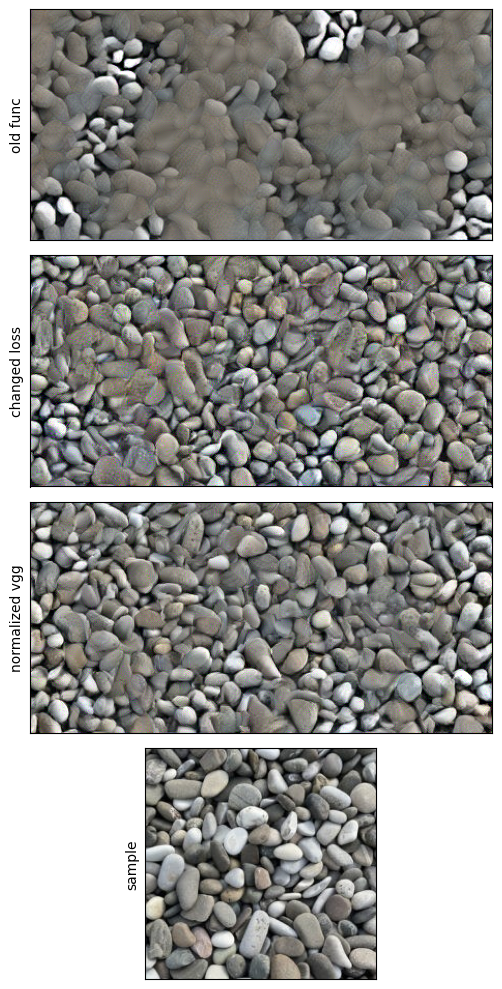

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(7, 10))
axes = axes.flatten()

axes[3].imshow(rock_texture.permute(1, 2, 0))
axes[3].set_xticks([])
axes[3].set_yticks([])
axes[3].set_ylabel('sample')

axes[0].imshow(texture_default.permute(1, 2, 0))
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].set_ylabel('old func')

axes[1].imshow(texture_loss.permute(1, 2, 0))
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_ylabel('changed loss')

axes[2].imshow(texture_norm.permute(1, 2, 0))
axes[2].set_xticks([])
axes[2].set_yticks([])
axes[2].set_ylabel('normalized vgg')

plt.tight_layout()
plt.show()

Можно заметить, что наша изначальная функция справляется с генерацией плохо. На генерируемом изображении много темных пятен, сами камни ярко-белые и крупные. На самом деле, это довольно естественно, когда мы меняем размеры генерируемого изображения, но не нормализуем лосс. В таком случае значения в матрицах Грама исходного изображения и генерируемого сильно отличаются в масштабах, а значит оптимизация будет приводить к непонятному результату в силу неверной лосс функции. Поэтому вторая генерация с измененной лосс функцией выглядит гораздо лучше первой.

Третья генерация уже с нормализованной сетью и измененной лосс функцией похожа на вторую, однако превосходит ее по качеству. Во второй генерации можно заметить лишний шум, неестественные тени и цвета на камнях.

Таким образом, получили модель, способную генерировать по примеру текстуру большего размера. Это впечатляет, ведь может иметь широкое применение в реальной жизни.

Интересно теперь оценить качество нашей текстуры с апельсинами с генерацией с помощью нормализованной VGG.

Шаг 0, loss = 350.38494873046875
Шаг 1, loss = 57.698543548583984
Шаг 2, loss = 24.62531280517578
Шаг 3, loss = 6.316600799560547
Шаг 4, loss = 2.6558475494384766
Шаг 5, loss = 1.392564058303833
Шаг 6, loss = 0.9302572011947632
Шаг 7, loss = 0.6576077938079834
Шаг 8, loss = 0.4922679662704468
Шаг 9, loss = 0.38731294870376587
Шаг 10, loss = 0.31798675656318665
Шаг 11, loss = 0.2681514024734497
Шаг 12, loss = 0.22998937964439392
Шаг 13, loss = 0.20297759771347046
Шаг 14, loss = 0.1813880056142807
Шаг 15, loss = 0.16454733908176422
Шаг 16, loss = 0.15229521691799164
Шаг 17, loss = 0.14129826426506042
Шаг 18, loss = 0.13201844692230225
Шаг 19, loss = 0.12406426668167114
Шаг 20, loss = 0.11763978749513626
Шаг 21, loss = 0.11234484612941742
Шаг 22, loss = 0.1074991524219513
Шаг 23, loss = 0.10317116975784302
Шаг 24, loss = 0.09952917695045471
Шаг 25, loss = 0.09624586254358292
Шаг 26, loss = 0.0935230478644371
Шаг 27, loss = 0.09089913964271545
Шаг 28, loss = 0.08868614584207535
Шаг 29, los

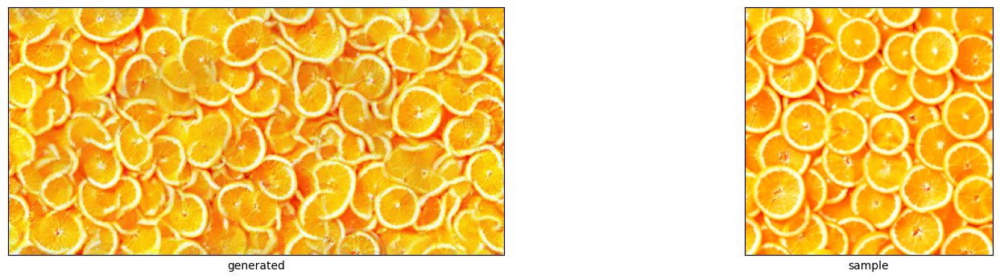

In [ ]:
orange_448_224 = generate_texture_normalized(work_img, weights, 448, 224, 100, device)

fig, axes = plt.subplots(1, 2, figsize=(18, 4))

axes[0].imshow(orange_448_224.permute(1, 2, 0))
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].set_xlabel('generated')

axes[1].imshow(work_img.permute(1, 2, 0))
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_xlabel('sample')

plt.show()

Конечно, модель не повторяет круги, и на генерации есть небольшие темные пятна с шумом, однако это вполне неплохо для 1 минуты генерации.

Остается посмотреть, как будет вести себя модель, если брать в качестве примера текстуру другого разрешения, большего чем 224 на 224. На это интересно посмотреть, поскольку модель VGG заточена архитектурой под маленькие изображения. Рассмотрим ту же текстуру камней, но большего разрешения (600 на 600). Это позволит разницу в генерации в зависимости от разрешения, ведь модель хорошо справляется с генерацией на основе изображения размера 224 на 224.

In [8]:
rock_large = Image.open('texture_src/rock_large.jpg').convert('RGB')
rock_large_texture = transforms.ToTensor()(rock_large)

In [20]:
def plot_generated(generated, sample):
  fig, axes = plt.subplots(1, 2, figsize=(10, 4))

  axes[0].imshow(generated.permute(1, 2, 0))
  axes[0].set_xticks([])
  axes[0].set_yticks([])
  axes[0].set_xlabel('generated')

  axes[1].imshow(sample.permute(1, 2, 0))
  axes[1].set_xticks([])
  axes[1].set_yticks([])
  axes[1].set_xlabel('sample')

  plt.show()

Шаг 0, loss = 255.08448791503906
Шаг 1, loss = 4.068030834197998
Шаг 2, loss = 1.8274481296539307
Шаг 3, loss = 1.022606611251831
Шаг 4, loss = 0.573995053768158
Шаг 5, loss = 0.37009403109550476
Шаг 6, loss = 0.27010414004325867
Шаг 7, loss = 0.20444820821285248
Шаг 8, loss = 0.16601552069187164
Шаг 9, loss = 0.1377497762441635
Шаг 10, loss = 0.1162625104188919
Шаг 11, loss = 0.10212069749832153
Шаг 12, loss = 0.089448943734169
Шаг 13, loss = 0.07956663519144058
Шаг 14, loss = 0.07177992165088654
Шаг 15, loss = 0.06524958461523056
Шаг 16, loss = 0.05981442332267761
Шаг 17, loss = 0.05490339547395706
Шаг 18, loss = 0.05085381865501404
Шаг 19, loss = 0.047249697148799896
Шаг 20, loss = 0.04382195323705673
Шаг 21, loss = 0.0408443808555603
Шаг 22, loss = 0.03823118284344673
Шаг 23, loss = 0.035922691226005554
Шаг 24, loss = 0.0334104485809803
Шаг 25, loss = 0.03135114908218384
Шаг 26, loss = 0.029537899419665337
Шаг 27, loss = 0.027804626151919365
Шаг 28, loss = 0.02631257474422455
Шаг 2

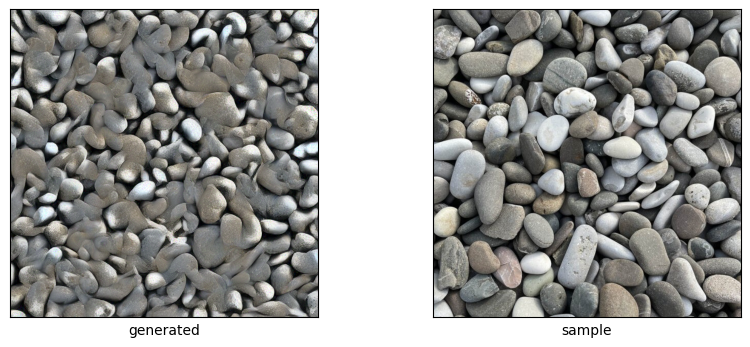

In [ ]:
generated_rock_large = generate_texture_normalized(rock_large_texture, weights, 600, 600, 100, device)

plot_generated(generated_rock_large, rock_large_texture)

Сгенерированная текстура далека по качеству от исходной. Видны очертания камней, однако они засветленные. Хочется попробовать добавить в учитываемые веса для лосса еще и слой из свертки на 5-й глубине. Попробуем.

Шаг 0, loss = 313.62945556640625
Шаг 1, loss = 15.04565143585205
Шаг 2, loss = 6.748627662658691
Шаг 3, loss = 4.40310525894165
Шаг 4, loss = 3.2601735591888428
Шаг 5, loss = 2.4992311000823975
Шаг 6, loss = 1.6799554824829102
Шаг 7, loss = 1.2331147193908691
Шаг 8, loss = 0.9598285555839539
Шаг 9, loss = 0.787723183631897
Шаг 10, loss = 0.6640509963035583
Шаг 11, loss = 0.5701212882995605
Шаг 12, loss = 0.49528998136520386
Шаг 13, loss = 0.43604856729507446
Шаг 14, loss = 0.38879284262657166
Шаг 15, loss = 0.35190722346305847
Шаг 16, loss = 0.3200294077396393
Шаг 17, loss = 0.29284611344337463
Шаг 18, loss = 0.2693343162536621
Шаг 19, loss = 0.24959483742713928
Шаг 20, loss = 0.23248764872550964
Шаг 21, loss = 0.21681779623031616
Шаг 22, loss = 0.20335236191749573
Шаг 23, loss = 0.1916426569223404
Шаг 24, loss = 0.18090039491653442
Шаг 25, loss = 0.17142514884471893
Шаг 26, loss = 0.16257399320602417
Шаг 27, loss = 0.15506844222545624
Шаг 28, loss = 0.1477300077676773
Шаг 29, loss = 0

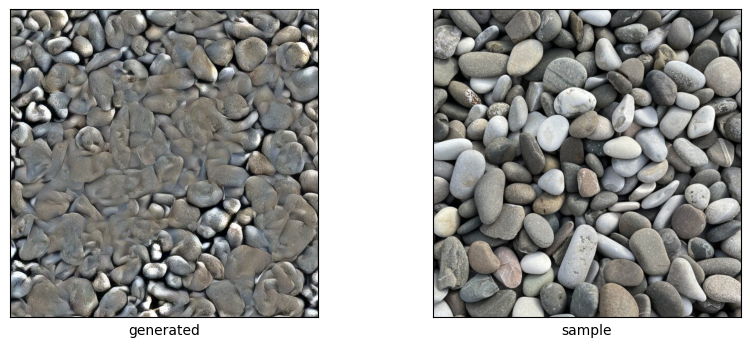

In [ ]:
weights[29] = 1
cnt_steps = 100

generated_rock_large_2 = generate_texture_normalized(rock_large_texture, weights, 600, 600, cnt_steps, device)

plot_generated(generated_rock_large_2, rock_large_texture)

Генерация совсем не удалась. Присутствуют проблемы с масштабом элементов, камни зашумленные. Возможно, я давал оптимизатору слишком мало итераций, ведь теперь изображение значительно больше и нужно больше времени. Так что попробуем добавить шагов.

Шаг 0, loss = 253376832.0
Шаг 1, loss = 3918932.0
Шаг 2, loss = 1889107.5
Шаг 3, loss = 1058252.375
Шаг 4, loss = 571954.5625
Шаг 5, loss = 377047.625
Шаг 6, loss = 266615.9375
Шаг 7, loss = 207392.46875
Шаг 8, loss = 164892.03125
Шаг 9, loss = 137734.25
Шаг 10, loss = 118120.9609375
Шаг 11, loss = 101905.859375
Шаг 12, loss = 90552.3359375
Шаг 13, loss = 80506.7890625
Шаг 14, loss = 71954.5703125
Шаг 15, loss = 65436.23046875
Шаг 16, loss = 60092.8984375
Шаг 17, loss = 55130.828125
Шаг 18, loss = 50576.3828125
Шаг 19, loss = 47044.921875
Шаг 20, loss = 43355.48046875
Шаг 21, loss = 40477.35546875
Шаг 22, loss = 37688.33984375
Шаг 23, loss = 35345.9296875
Шаг 24, loss = 33258.26171875
Шаг 25, loss = 31387.119140625
Шаг 26, loss = 29449.015625
Шаг 27, loss = 27712.94921875
Шаг 28, loss = 26227.03125
Шаг 29, loss = 24789.31640625
Шаг 30, loss = 23547.03125
Шаг 31, loss = 22280.416015625
Шаг 32, loss = 21068.7890625
Шаг 33, loss = 19978.576171875
Шаг 34, loss = 18838.33203125
Шаг 35, loss

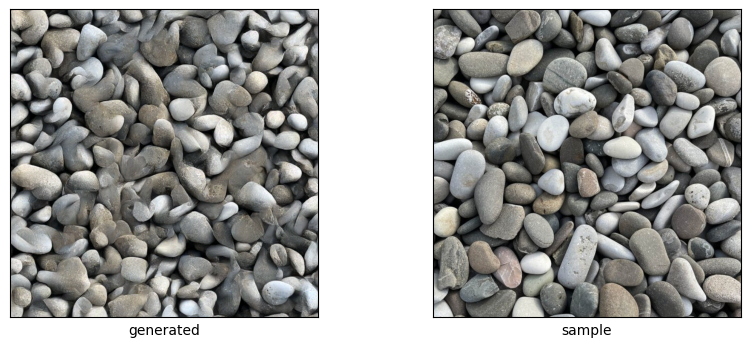

In [26]:
cnt_steps = 1000
generated_rock_large_3 = generate_texture_normalized(rock_large_texture, {1 : 1e6, 6 : 1e6, 11 : 1e6, 20 : 1e6}, 600, 600, cnt_steps, device)

plot_generated(generated_rock_large_3, rock_large_texture)

В этот раз текстура получилась ближе к оригиналу, здесь уже камни разнообразные, имеют форму, хоть и немного сливаются. Теперь я доволен результатом. Помимо добавления шагов оптимизатору, я еще и изменил веса для лосса. Это я увидел в коде генерации текстуры от автора статьи. Предполагаю, что дает более стабильные вычисления, а также лосс становится более выразительным для человека. Стоит отметить, что генерация заняла почти час, а именно 54 минуты. Это, безусловно, очень долго для приложений в жизни.

**Выводы:**

Я реализовал модель, способную генерировать по примеру текстуры новое изображение с той же самой текстурой. Реализация была основана на статье, упомянутой в начале файла.

Полученную модель я далее буду применять в алгоритме нейронного переноса стиля, однако она интересна по-своему.

В первую очередь я проверил результаты статьи в смысле нахождения тех слоев, что дают наиболее привлекательные результаты генерации. Эксперименты показали, что к таким комбинациями слоев подходят (conv1_1, conv2_1, conv3_1, conv4_1) и далее ее включающие, например, все слои до pool4, или с добавлением к ним conv5_1. Однако, разница между ними в качестве не очень существенна. При этом комбинация (conv1_1, conv2_1, conv3_1, conv4_1) требует меньше вычислений.

Было выяснено модель хорошо справляет с текстурами, где нет строгих форм. Об этом говорит ее успех с текстурами травы или гальки и неуспех с текстурой нарезанных апельсинов. Еще была проверена генерация на основе картины Ван Гога, где модель успешно справилась, дала изображение в стиле картины, хоть и бессмысленное по содержанию.

В отличие от статьи, я провел еще несколько экспериментов. Для практического применения хочется генерировать текстуры большего размера. Я понял, что модель позволяет это делать без каких-либо препятствий. На этом этапе возникли проблемы с качеством и скоростью генерации. Нашлось два решения, которые в совокупности дали красивый результат. Во-первых, нужно было нормализовать элементы матрицы Грама, чтобы значения в матрицах Грама исходной текстуры и генерируемой были сопоставимого масштаба. Во-вторых, нужно было сделать нормализацию весов сети, чтобы лоссы с разных слоев давали одинаковый вклад в итоговый лосс. Так что дополнительно я реализовал нормализованную версию VGG.

Далее, нужно было проверить, умеет ли модель использовать в качестве примера изображения большого разрешения. Оказалось, что никаких препятствий нет, только кратно увеличивается время генерации.

В этой работе вычислительная проблема самая важная, ведь не позволяет эффективно внедрять это в жизнь. Кажется, что эта проблема была решена еще в течение 2-х лет после публикации статьи, на основе которой я проводил исследование.
